# Diplomatura en ciencia de datos, aprendizaje automático y sus aplicaciones

## Edición 2026 - Optativa: Aprendizaje por Refuerzo

Profesores: Jorge Palombarini y Juan Barsce

---

# Modelos RL offline Decision Transformers (DT) e Implicit Q-Lerning (IQL)

Autor: Gonzalo Perez Paina

Enlaces:
- [Repositorio de la materia](https://github.com/DiploDatos/AprendizajePorRefuerzos/)
- [Consigna del Trabajo Práctico](https://github.com/DiploDatos/AprendizajePorRefuerzos/blob/master/2026/tp/CONSIGNA.md)

## Acceso al dataset y módulos Python base

Las siguientes celdas  permiten trabajar con los datos y módulos Python desde el repositorio de (elaboradas con Claude).

In [1]:
import os, sys, importlib
REPO = "DiploDatos/AprendizajePorRefuerzos"

In [2]:
RAIZ = "/content/" + REPO.split("/")[1]          # raíz del repo (clone / pull)
TRABAJO = os.path.join(RAIZ, "2026", "tp")       # directorio de trabajo

if not os.path.exists(RAIZ):
    !git clone -q https://github.com/{REPO}.git {RAIZ}
else:
    !git -C {RAIZ} pull -q

%cd {TRABAJO}
if os.path.exists("requirements.txt"):
    !pip install -q -r requirements.txt
sys.path.insert(0, TRABAJO)                      # para "import protocolo..."

# Parche: el autoreload de IPython en Colab todavía importa 'imp' (eliminado en Python 3.12+)
sys.modules.setdefault("imp", importlib)
%load_ext autoreload
%autoreload 2

/content/AprendizajePorRefuerzos/2026/tp


## Acceso a los scripts de entrenamiento y validación

A continuación se accede a la implementación contenida en un archivo ZIP y se descomprime:

In [3]:
import os, shutil, sys, time, zipfile, urllib.request

ZIP_URL = "https://github.com/Mariano-ds/tpRL_2026/raw/refs/heads/main/gonzalo/modelos.zip"
ZIP_LOCAL = "/content/modelos.zip"
DESTINO = os.path.join(TRABAJO, "modelos")

# Descarga. El parámetro ?t= evita recibir una copia en caché si se acaba de hacer push.
urllib.request.urlretrieve(f"{ZIP_URL}?t={int(time.time())}", ZIP_LOCAL)

with zipfile.ZipFile(ZIP_LOCAL) as zf:
    nombres = zf.namelist()
    # El ZIP debe tener 'modelos/' en la raíz y ninguna ruta que salga de esa carpeta
    assert nombres and all(n.startswith("modelos/") and ".." not in n for n in nombres), \
        "Estructura inesperada: la raíz del ZIP debe ser 'modelos/'"
    shutil.rmtree(DESTINO, ignore_errors=True)   # borra la versión anterior, para no dejar archivos viejos
    zf.extractall(TRABAJO)                       # queda como 2026/tp/modelos/...

# Si 'modelos' ya estaba importado, se descarta para que el próximo import use el código nuevo
for m in [m for m in sys.modules if m == "modelos" or m.startswith("modelos.")]:
    del sys.modules[m]

print(f"{len(nombres)} archivos extraídos en {DESTINO}")
!ls {DESTINO}

14 archivos extraídos en /content/AprendizajePorRefuerzos/2026/tp/modelos
comun.py       entrenar.py	  experimentos.py  README.md
dt.py	       evaluar_lotes.py   __init__.py	   reporte.py
empaquetar.py  evaluar_modelo.py  iql.py	   tests


Verificación:

In [10]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
import numpy, pandas
print("numpy", numpy.__version__, "| pandas", pandas.__version__)
correr("python -m pytest -q modelos/tests protocolo/tests")   # no fuga del DT y equivalencia del evaluador por lotes

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
numpy 2.4.6 | pandas 2.2.3
.....................................................                    [100%]
53 passed in 31.41s


In [5]:
!python -m pytest -q modelos/tests

..................................                                       [100%]
34 passed in 42.47s


## Ejecución completa

### 1. Configuración: Drive, GPU y función de ejecución



In [4]:
import os, subprocess, shlex, json, datetime
import torch
from google.colab import drive

drive.mount("/content/drive")

DATASET = "netflix"
BASE_DRIVE = "/content/drive/MyDrive/tp_rl_2026"        # carpeta del TP en Drive
os.environ["TP_OUTPUTS"] = f"{BASE_DRIVE}/outputs/modelos"   # checkpoints, evaluaciones y tablas
os.environ["PYTHONUNBUFFERED"] = "1"                     # salida en vivo de los subprocesos
os.makedirs(os.environ["TP_OUTPUTS"], exist_ok=True)
LOG = f"{BASE_DRIVE}/ejecucion.log"

assert torch.cuda.is_available(), "Sin GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU"
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)
print("Resultados en:", os.environ["TP_OUTPUTS"])

def correr(cmd: str) -> None:
    """Ejecuta un comando desde 2026/tp, muestra la salida en vivo y la guarda en el log de Drive."""
    with open(LOG, "a", encoding="utf-8") as fh:
        fh.write(f"\n=== {datetime.datetime.now():%Y-%m-%d %H:%M:%S}  $ {cmd}\n")
        p = subprocess.Popen(shlex.split(cmd), cwd=TRABAJO, env=os.environ, text=True, bufsize=1,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        for line in p.stdout:
            print(line, end="")
            fh.write(line)
        if p.wait() != 0:
            raise RuntimeError(f"Falló (código {p.returncode}): {cmd}. Ver {LOG}")

Mounted at /content/drive
GPU: Tesla T4 | torch 2.14.1+cu130
Resultados en: /content/drive/MyDrive/tp_rl_2026/outputs/modelos


### 2. Entrenamiento y validación con logs random


In [7]:
# DT, semilla 0: se entrena (checkpoint con menor cross-entropy en val) y se evalúan en val
# los retornos pedidos (percentiles de train, máximo y dos valores fuera del soporte).
correr(f"python -m modelos.experimentos barrido-dt --dataset {DATASET} --logs random")

# IQL, semilla 0: 8 configuraciones (γ ∈ {0; 0,9} × τ ∈ {0,7; 0,9} × β ∈ {3; 10}),
# cada una evaluada en val con π y con el máximo de Q.
correr(f"python -m modelos.experimentos barrido-iql --dataset {DATASET} --logs random")

Entreno /content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_random/dt/base/seed0
{'epoch': 1, 'step': 289, 'seconds': 12.9, 'train_ce': 6.6184, 'train_acc': 0.0013, 'val_ce': 6.613, 'val_acc': 0.0014}
{'epoch': 2, 'step': 578, 'seconds': 23.8, 'train_ce': 6.6136, 'train_acc': 0.0013, 'val_ce': 6.6139, 'val_acc': 0.0013}
{'epoch': 3, 'step': 867, 'seconds': 34.8, 'train_ce': 6.6122, 'train_acc': 0.0014, 'val_ce': 6.6119, 'val_acc': 0.0014}
{'epoch': 4, 'step': 1156, 'seconds': 45.9, 'train_ce': 6.6102, 'train_acc': 0.0015, 'val_ce': 6.6111, 'val_acc': 0.0015}
{'epoch': 5, 'step': 1445, 'seconds': 57.1, 'train_ce': 6.6067, 'train_acc': 0.0016, 'val_ce': 6.6002, 'val_acc': 0.0019}
{'epoch': 6, 'step': 1734, 'seconds': 68.3, 'train_ce': 6.5936, 'train_acc': 0.0019, 'val_ce': 6.5899, 'val_acc': 0.0017}
{'epoch': 7, 'step': 2023, 'seconds': 79.7, 'train_ce': 6.5869, 'train_acc': 0.0021, 'val_ce': 6.5892, 'val_acc': 0.0017}
{'epoch': 8, 'step': 2312, 'seconds': 91.1, 'train_ce': 6.5833,

### 3. Barrido del DT con logs mixto

In [8]:
# Genera los logs "mixto" la primera vez (≈1 min; quedan en Drive), entrena el DT con ellos
# y elige en val su retorno pedido. Los hiperparámetros de IQL se toman del barrido con logs random.
correr(f"python -m modelos.experimentos barrido-dt --dataset {DATASET} --logs mixto")

Entreno /content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/dt/base/seed0
{'epoch': 1, 'step': 289, 'seconds': 11.5, 'train_ce': 6.4454, 'train_acc': 0.0054, 'val_ce': 6.3286, 'val_acc': 0.0063}
{'epoch': 2, 'step': 578, 'seconds': 22.5, 'train_ce': 6.2746, 'train_acc': 0.0065, 'val_ce': 6.1946, 'val_acc': 0.0058}
{'epoch': 3, 'step': 867, 'seconds': 33.5, 'train_ce': 6.238, 'train_acc': 0.0068, 'val_ce': 6.1824, 'val_acc': 0.0065}
{'epoch': 4, 'step': 1156, 'seconds': 44.6, 'train_ce': 6.2276, 'train_acc': 0.007, 'val_ce': 6.176, 'val_acc': 0.0067}
{'epoch': 5, 'step': 1445, 'seconds': 55.8, 'train_ce': 6.2113, 'train_acc': 0.0072, 'val_ce': 6.1609, 'val_acc': 0.0069}
{'epoch': 6, 'step': 1734, 'seconds': 67.1, 'train_ce': 6.1891, 'train_acc': 0.0074, 'val_ce': 6.1545, 'val_acc': 0.0071}
{'epoch': 7, 'step': 2023, 'seconds': 78.5, 'train_ce': 6.1756, 'train_acc': 0.0075, 'val_ce': 6.1466, 'val_acc': 0.0071}
{'epoch': 8, 'step': 2312, 'seconds': 90.0, 'train_ce': 6.1675, 't

### 4. Hiperparámetros elegidos en validación

In [9]:
import pandas as pd

def mostrar(logs, modelo):
    base = f"{os.environ['TP_OUTPUTS']}/{DATASET}_{logs}/barridos/{modelo}"
    if not os.path.exists(f"{base}/elegido.json"):
        print(f"[{logs}/{modelo}] todavía no se ejecutó")
        return
    print(f"\n=== {logs} / {modelo}: normalized en val (promedio = criterio de selección)")
    display(pd.read_csv(f"{base}/puntajes.csv", index_col=0).round(3))
    sel = json.load(open(f"{base}/elegido.json"))
    print("Elegido:", sel.get("target", sel.get("best")))

for logs, modelo in [("random", "dt"), ("random", "iql"), ("mixto", "dt")]:
    mostrar(logs, modelo)


=== random / dt: normalized en val (promedio = criterio de selección)


,w0_oculto,w0_vis,w5_oculto,w5_vis,promedio
policy,,,,,
dt_R117,0.556,0.561,0.572,0.574,0.566
dt_R107,0.556,0.561,0.571,0.574,0.566
dt_R97,0.550,0.560,0.569,0.577,0.564
dt_R89,0.487,0.512,0.531,0.545,0.519
dt_R81,0.346,0.371,0.394,0.411,0.380
dt_R73,0.151,0.165,0.174,0.183,0.168
dt_R65,-0.053,-0.058,-0.073,-0.072,-0.064
dt_R57,-0.251,-0.269,-0.307,-0.319,-0.287
dt_R46,-0.464,-0.502,-0.529,-0.562,-0.514


Elegido: 117.0

=== random / iql: normalized en val (promedio = criterio de selección)


,w0_oculto,w0_vis,w5_oculto,w5_vis,promedio
policy,,,,,
iql_g0_t0.9_b3_q,0.572,0.651,0.589,0.657,0.617
iql_g0_t0.7_b3_q,0.572,0.651,0.589,0.657,0.617
iql_g0_t0.9_b10_q,0.570,0.650,0.587,0.657,0.616
iql_g0_t0.7_b10_q,0.566,0.651,0.583,0.656,0.614
iql_g0_t0.7_b10_pi,0.548,0.648,0.573,0.656,0.606
iql_g0_t0.7_b3_pi,0.544,0.649,0.570,0.660,0.606
iql_g0.9_t0.7_b10_pi,0.559,0.642,0.574,0.648,0.606
iql_g0.9_t0.9_b3_pi,0.548,0.648,0.570,0.656,0.605
iql_g0_t0.9_b3_pi,0.543,0.650,0.569,0.660,0.605


Elegido: {'gamma': 0.0, 'tau': 0.7, 'beta': 10.0}

=== mixto / dt: normalized en val (promedio = criterio de selección)


,w0_oculto,w0_vis,w5_oculto,w5_vis,promedio
policy,,,,,
dt_R99,0.552,0.633,0.568,0.640,0.598
dt_R95,0.546,0.635,0.561,0.645,0.597
dt_R109,0.554,0.625,0.572,0.633,0.596
dt_R119,0.556,0.619,0.571,0.627,0.593
dt_R89,0.530,0.595,0.548,0.621,0.574
dt_R84,0.498,0.514,0.512,0.545,0.517
dt_R77,0.425,0.329,0.398,0.361,0.378
dt_R67,0.289,0.036,0.118,0.020,0.116
dt_R57,0.146,-0.252,-0.222,-0.311,-0.160


Elegido: 99.0


### 5. Corridas finales con logs random (3 semillas, test)

In [11]:
# Entrena las semillas 1 y 2 del DT y de las dos configuraciones de IQL elegidas en val
# (la mejor con cada γ, para comparar γ = 0 con γ > 0). La semilla 0 se reutiliza del barrido.
# Evalúa una sola vez en test, en las 4 condiciones y con 3 semillas de sesión: líneas base,
# DT con todos los retornos del barrido (return conditioning), IQL π e IQL máximo de Q.
# Al terminar genera la tabla final.
correr(f"python -m modelos.experimentos final --dataset {DATASET} --logs random")

                                      return  normalized  hit_rate  ndcg@10
policy          warmup group_visible                                       
group_mean      0      False          88.421       0.689     0.894    0.924
                       True           90.066       0.742     0.918    0.936
                5      False          66.735       0.705     0.904    0.923
                       True           67.767       0.749     0.923    0.936
group_posterior 0      False          88.894       0.707     0.896    0.924
                       True           90.066       0.742     0.918    0.936
                5      False          67.271       0.729     0.911    0.927
                       True           67.767       0.749     0.923    0.936
item_mean       0      False          88.421       0.689     0.894    0.924
                       True           88.421       0.689     0.894    0.924
                5      False          66.735       0.705     0.904    0.923
            

### 6. Corridas finales con logs mixto (calidad de los logs)

In [5]:
# Mismos hiperparámetros de IQL que con logs random (--hp-de random). El retorno pedido al DT
# es el elegido en val con logs mixto (celda 3). Las líneas base se ajustan con los logs mixto,
# y se agrega el sistema anterior (ε = 0) como referencia. --no-rc: con logs mixto sólo se
# evalúa en test el retorno elegido.
correr(f"python -m modelos.experimentos final --dataset {DATASET} --logs mixto --hp-de random --no-rc")

Ya evaluado: /content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/final/test/seed0
Ya evaluado: /content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/final/test/seed1
Ya evaluado: /content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/final/test/seed2
### netflix, logs `mixto`, test — `normalized`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | -0.002 [IC ±0.005] | -0.002 [IC ±0.005] | 0.003 [IC ±0.006] | 0.003 [IC ±0.006] |
| `popularity` | 0.688 [IC ±0.005] | 0.688 [IC ±0.005] | 0.704 [IC ±0.005] | 0.704 [IC ±0.005] |
| `item_mean` | 0.672 [IC ±0.006] | 0.672 [IC ±0.006] | 0.695 [IC ±0.006] | 0.695 [IC ±0.006] |
| `group_mean` | 0.741 [IC ±0.005] | 0.672 [IC ±0.006] | 0.750 [IC ±0.005] | 0.695 [IC ±0.006] |
| `group_posterior` | 0.741 [IC ±0.005] | 0.705 [IC ±0.005] | 0.750 [IC ±0.005] | 0.727 [IC ±0.005] |

### 7. Reportes y gráficos

### netflix, logs `random`, test — `normalized`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | -0.002 [IC ±0.005] | -0.002 [IC ±0.005] | 0.003 [IC ±0.006] | 0.003 [IC ±0.006] |
| `popularity` | -0.058 [IC ±0.007] | -0.058 [IC ±0.007] | -0.117 [IC ±0.009] | -0.117 [IC ±0.009] |
| `item_mean` | 0.689 [IC ±0.005] | 0.689 [IC ±0.005] | 0.705 [IC ±0.005] | 0.705 [IC ±0.005] |
| `group_mean` | 0.742 [IC ±0.005] | 0.689 [IC ±0.005] | 0.749 [IC ±0.005] | 0.705 [IC ±0.005] |
| `group_posterior` | 0.742 [IC ±0.005] | 0.707 [IC ±0.005] | 0.749 [IC ±0.005] | 0.729 [IC ±0.005] |
| DT (R̂ = 117, elegido en val.) | 0.683 ± 0.002 [IC ±0.005] | 0.676 ± 0.011 [IC ±0.005] | 0.700 ± 0.002 [IC ±0.006] | 0.695 ± 0.002 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.703 ± 0.006 [IC ±0.006] | 0.643 ± 0.007 [IC ±0.006] | 0.708 ± 0.004 [IC ±0.006] | 0.687 ± 0.003 [IC 

### netflix, logs `random`, test — `normalized`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | -0.002 [IC ±0.005] | -0.002 [IC ±0.005] | 0.003 [IC ±0.006] | 0.003 [IC ±0.006] |
| `popularity` | -0.058 [IC ±0.007] | -0.058 [IC ±0.007] | -0.117 [IC ±0.009] | -0.117 [IC ±0.009] |
| `item_mean` | 0.689 [IC ±0.005] | 0.689 [IC ±0.005] | 0.705 [IC ±0.005] | 0.705 [IC ±0.005] |
| `group_mean` | 0.742 [IC ±0.005] | 0.689 [IC ±0.005] | 0.749 [IC ±0.005] | 0.705 [IC ±0.005] |
| `group_posterior` | 0.742 [IC ±0.005] | 0.707 [IC ±0.005] | 0.749 [IC ±0.005] | 0.729 [IC ±0.005] |
| DT (R̂ = 117, elegido en val.) | 0.683 ± 0.002 [IC ±0.005] | 0.676 ± 0.011 [IC ±0.005] | 0.700 ± 0.002 [IC ±0.006] | 0.695 ± 0.002 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.703 ± 0.006 [IC ±0.006] | 0.643 ± 0.007 [IC ±0.006] | 0.708 ± 0.004 [IC ±0.006] | 0.687 ± 0.003 [IC ±0.005] |
| IQL máx. Q, γ = 0 (elegido) | 0.728 ± 0.002 [IC ±0.005] | 0.669 ± 0.010 [IC ±0.005] | 0.736 ± 0.004 [IC ±0.005] | 0.694 ± 0.007 [IC ±0.005] |
| IQL π, γ = 0.9 | 0.702 ± 0.005 [IC ±0.006] | 0.653 ± 0.009 [IC ±0.005] | 0.705 ± 0.006 [IC ±0.006] | 0.674 ± 0.005 [IC ±0.006] |
| IQL máx. Q, γ = 0.9 | 0.700 ± 0.006 [IC ±0.005] | 0.643 ± 0.018 [IC ±0.005] | 0.711 ± 0.003 [IC ±0.005] | 0.675 ± 0.014 [IC ±0.005] |


### netflix, logs `random`, test — `hit_rate`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.463 [IC ±0.010] | 0.463 [IC ±0.010] |
| `popularity` | 0.429 [IC ±0.009] | 0.429 [IC ±0.009] | 0.396 [IC ±0.009] | 0.396 [IC ±0.009] |
| `item_mean` | 0.894 [IC ±0.006] | 0.894 [IC ±0.006] | 0.904 [IC ±0.006] | 0.904 [IC ±0.006] |
| `group_mean` | 0.918 [IC ±0.006] | 0.894 [IC ±0.006] | 0.923 [IC ±0.006] | 0.904 [IC ±0.006] |
| `group_posterior` | 0.918 [IC ±0.006] | 0.896 [IC ±0.006] | 0.923 [IC ±0.006] | 0.911 [IC ±0.006] |
| DT (R̂ = 117, elegido en val.) | 0.886 ± 0.002 [IC ±0.006] | 0.882 ± 0.006 [IC ±0.006] | 0.898 ± 0.002 [IC ±0.006] | 0.894 ± 0.001 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.887 ± 0.002 [IC ±0.007] | 0.847 ± 0.007 [IC ±0.007] | 0.888 ± 0.001 [IC ±0.007] | 0.879 ± 0.004 [IC ±0.006] 

### netflix, logs `random`, test — `hit_rate`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.463 [IC ±0.010] | 0.463 [IC ±0.010] |
| `popularity` | 0.429 [IC ±0.009] | 0.429 [IC ±0.009] | 0.396 [IC ±0.009] | 0.396 [IC ±0.009] |
| `item_mean` | 0.894 [IC ±0.006] | 0.894 [IC ±0.006] | 0.904 [IC ±0.006] | 0.904 [IC ±0.006] |
| `group_mean` | 0.918 [IC ±0.006] | 0.894 [IC ±0.006] | 0.923 [IC ±0.006] | 0.904 [IC ±0.006] |
| `group_posterior` | 0.918 [IC ±0.006] | 0.896 [IC ±0.006] | 0.923 [IC ±0.006] | 0.911 [IC ±0.006] |
| DT (R̂ = 117, elegido en val.) | 0.886 ± 0.002 [IC ±0.006] | 0.882 ± 0.006 [IC ±0.006] | 0.898 ± 0.002 [IC ±0.006] | 0.894 ± 0.001 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.887 ± 0.002 [IC ±0.007] | 0.847 ± 0.007 [IC ±0.007] | 0.888 ± 0.001 [IC ±0.007] | 0.879 ± 0.004 [IC ±0.006] |
| IQL máx. Q, γ = 0 (elegido) | 0.914 ± 0.001 [IC ±0.006] | 0.872 ± 0.007 [IC ±0.006] | 0.919 ± 0.002 [IC ±0.006] | 0.890 ± 0.005 [IC ±0.006] |
| IQL π, γ = 0.9 | 0.891 ± 0.005 [IC ±0.007] | 0.859 ± 0.009 [IC ±0.007] | 0.893 ± 0.005 [IC ±0.007] | 0.874 ± 0.006 [IC ±0.007] |
| IQL máx. Q, γ = 0.9 | 0.902 ± 0.005 [IC ±0.006] | 0.858 ± 0.010 [IC ±0.006] | 0.911 ± 0.004 [IC ±0.006] | 0.883 ± 0.008 [IC ±0.006] |


### netflix, logs `random`, test — `ndcg@10`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] |
| `popularity` | 0.412 [IC ±0.010] | 0.412 [IC ±0.010] | 0.411 [IC ±0.010] | 0.411 [IC ±0.010] |
| `item_mean` | 0.924 [IC ±0.006] | 0.924 [IC ±0.006] | 0.923 [IC ±0.006] | 0.923 [IC ±0.006] |
| `group_mean` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.923 [IC ±0.006] |
| `group_posterior` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.927 [IC ±0.006] |
| DT (R̂ = 117, elegido en val.) | 0.915 ± 0.004 [IC ±0.006] | 0.880 ± 0.039 [IC ±0.007] | 0.918 ± 0.003 [IC ±0.006] | 0.908 ± 0.016 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.890 ± 0.001 [IC ±0.008] | 0.894 ± 0.004 [IC ±0.007] | 0.893 ± 0.003 [IC ±0.008] | 0.900 ± 0.001 [IC ±0.007] |

### netflix, logs `random`, test — `ndcg@10`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] |
| `popularity` | 0.412 [IC ±0.010] | 0.412 [IC ±0.010] | 0.411 [IC ±0.010] | 0.411 [IC ±0.010] |
| `item_mean` | 0.924 [IC ±0.006] | 0.924 [IC ±0.006] | 0.923 [IC ±0.006] | 0.923 [IC ±0.006] |
| `group_mean` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.923 [IC ±0.006] |
| `group_posterior` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.927 [IC ±0.006] |
| DT (R̂ = 117, elegido en val.) | 0.915 ± 0.004 [IC ±0.006] | 0.880 ± 0.039 [IC ±0.007] | 0.918 ± 0.003 [IC ±0.006] | 0.908 ± 0.016 [IC ±0.006] |
| IQL π, γ = 0 (elegido) | 0.890 ± 0.001 [IC ±0.008] | 0.894 ± 0.004 [IC ±0.007] | 0.893 ± 0.003 [IC ±0.008] | 0.900 ± 0.001 [IC ±0.007] |
| IQL máx. Q, γ = 0 (elegido) | 0.931 ± 0.001 [IC ±0.006] | 0.918 ± 0.001 [IC ±0.006] | 0.930 ± 0.003 [IC ±0.006] | 0.918 ± 0.002 [IC ±0.006] |
| IQL π, γ = 0.9 | 0.887 ± 0.005 [IC ±0.008] | 0.837 ± 0.009 [IC ±0.009] | 0.892 ± 0.001 [IC ±0.008] | 0.876 ± 0.005 [IC ±0.007] |
| IQL máx. Q, γ = 0.9 | 0.916 ± 0.003 [IC ±0.006] | 0.911 ± 0.012 [IC ±0.006] | 0.914 ± 0.007 [IC ±0.006] | 0.907 ± 0.007 [IC ±0.006] |


... (3 outputs left out)

### netflix, logs `mixto`, test — `hit_rate`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.463 [IC ±0.010] | 0.463 [IC ±0.010] |
| `popularity` | 0.893 [IC ±0.006] | 0.893 [IC ±0.006] | 0.902 [IC ±0.006] | 0.902 [IC ±0.006] |
| `item_mean` | 0.873 [IC ±0.007] | 0.873 [IC ±0.007] | 0.892 [IC ±0.007] | 0.892 [IC ±0.007] |
| `group_mean` | 0.917 [IC ±0.006] | 0.873 [IC ±0.007] | 0.923 [IC ±0.006] | 0.892 [IC ±0.007] |
| `group_posterior` | 0.917 [IC ±0.006] | 0.897 [IC ±0.006] | 0.923 [IC ±0.006] | 0.911 [IC ±0.006] |
| `sistema_anterior_eps0` | 0.837 [IC ±0.006] | 0.791 [IC ±0.008] | 0.839 [IC ±0.006] | 0.792 [IC ±0.008] |
| DT (R̂ = 99, elegido en val.) | 0.911 ± 0.003 [IC ±0.006] | 0.884 ± 0.007 [IC ±0.007] | 0.918 ± 0.004 [IC ±0.006] | 0.885 ± 0.004 [IC ±0.007] |
| IQL π, γ = 0 (elegido) | 0.914 ± 0.002 [IC ±0.006] | 0.877 ± 0.010 [IC ±0.006] | 0.921 ± 0.001 [IC ±0.006] | 0.898 ± 0.004 [IC ±0.006] |
| IQL máx. Q, γ = 0 (elegido) | 0.914 ± 0.002 [IC ±0.006] | 0.879 ± 0.004 [IC ±0.006] | 0.920 ± 0.001 [IC ±0.006] | 0.889 ± 0.003 [IC ±0.006] |
| IQL π, γ = 0.9 | 0.914 ± 0.001 [IC ±0.006] | 0.874 ± 0.001 [IC ±0.006] | 0.920 ± 0.002 [IC ±0.006] | 0.895 ± 0.003 [IC ±0.006] |
| IQL máx. Q, γ = 0.9 | 0.906 ± 0.001 [IC ±0.006] | 0.811 ± 0.020 [IC ±0.007] | 0.914 ± 0.002 [IC ±0.006] | 0.860 ± 0.009 [IC ±0.006] |


### netflix, logs `mixto`, test — `ndcg@10`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] |
| `popularity` | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] |
| `item_mean` | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] |
| `group_mean` | 0.936 [IC ±0.006] | 0.920 [IC ±0.006] | 0.936 [IC ±0.006] | 0.920 [IC ±0.006] |
| `group_posterior` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.927 [IC ±0.006] |
| `sistema_anterior_eps0` | 0.839 [IC ±0.006] | 0.794 [IC ±0.008] | 0.842 [IC ±0.006] | 0.797 [IC ±0.008] |
| DT (R̂ = 99, elegido en val.) | 0.935 ± 0.002 [IC ±0.006] | 0.836 ± 0.032 [IC ±0.009] | 0.933 ± 0.002 [IC ±0.006] | 0.873 ± 0.013 [IC ±0.007] |
| IQL π, γ = 0 (elegido) | 0.935

### netflix, logs `mixto`, test — `ndcg@10`

media entre semillas de entrenamiento ± desvío entre semillas [IC 95 % por usuario]

| Política | Visible | Oculto | Warm-up 5, visible | Warm-up 5, oculto |
|---|---:|---:|---:|---:|
| `random` | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] | 0.459 [IC ±0.010] |
| `popularity` | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] | 0.925 [IC ±0.006] |
| `item_mean` | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] | 0.920 [IC ±0.006] |
| `group_mean` | 0.936 [IC ±0.006] | 0.920 [IC ±0.006] | 0.936 [IC ±0.006] | 0.920 [IC ±0.006] |
| `group_posterior` | 0.936 [IC ±0.006] | 0.924 [IC ±0.006] | 0.936 [IC ±0.006] | 0.927 [IC ±0.006] |
| `sistema_anterior_eps0` | 0.839 [IC ±0.006] | 0.794 [IC ±0.008] | 0.842 [IC ±0.006] | 0.797 [IC ±0.008] |
| DT (R̂ = 99, elegido en val.) | 0.935 ± 0.002 [IC ±0.006] | 0.836 ± 0.032 [IC ±0.009] | 0.933 ± 0.002 [IC ±0.006] | 0.873 ± 0.013 [IC ±0.007] |
| IQL π, γ = 0 (elegido) | 0.935 ± 0.000 [IC ±0.006] | 0.918 ± 0.004 [IC ±0.006] | 0.925 ± 0.003 [IC ±0.006] | 0.917 ± 0.002 [IC ±0.006] |
| IQL máx. Q, γ = 0 (elegido) | 0.931 ± 0.001 [IC ±0.006] | 0.904 ± 0.008 [IC ±0.007] | 0.932 ± 0.001 [IC ±0.006] | 0.909 ± 0.002 [IC ±0.006] |
| IQL π, γ = 0.9 | 0.935 ± 0.001 [IC ±0.006] | 0.914 ± 0.004 [IC ±0.006] | 0.916 ± 0.004 [IC ±0.007] | 0.900 ± 0.003 [IC ±0.006] |
| IQL máx. Q, γ = 0.9 | 0.928 ± 0.002 [IC ±0.006] | 0.853 ± 0.015 [IC ±0.009] | 0.928 ± 0.002 [IC ±0.006] | 0.896 ± 0.009 [IC ±0.006] |


                                  media            desvio_semillas           
                            full_return normalized     full_return normalized
pedido warmup group_visible                                                  
46.0   0      False              49.444     -0.543           0.381      0.015
              True               47.860     -0.606           0.130      0.005
       5      False              50.730     -0.649           0.399      0.019
              True               49.449     -0.706           0.144      0.009
57.0   0      False              58.209     -0.296           0.102      0.005
              True               57.509     -0.335           0.076      0.004
       5      False              58.592     -0.366           0.139      0.008
              True               58.085     -0.401           0.030      0.002
65.0   0      False              65.217     -0.086           0.014      0.001
              True               65.047     -0.107           0.0

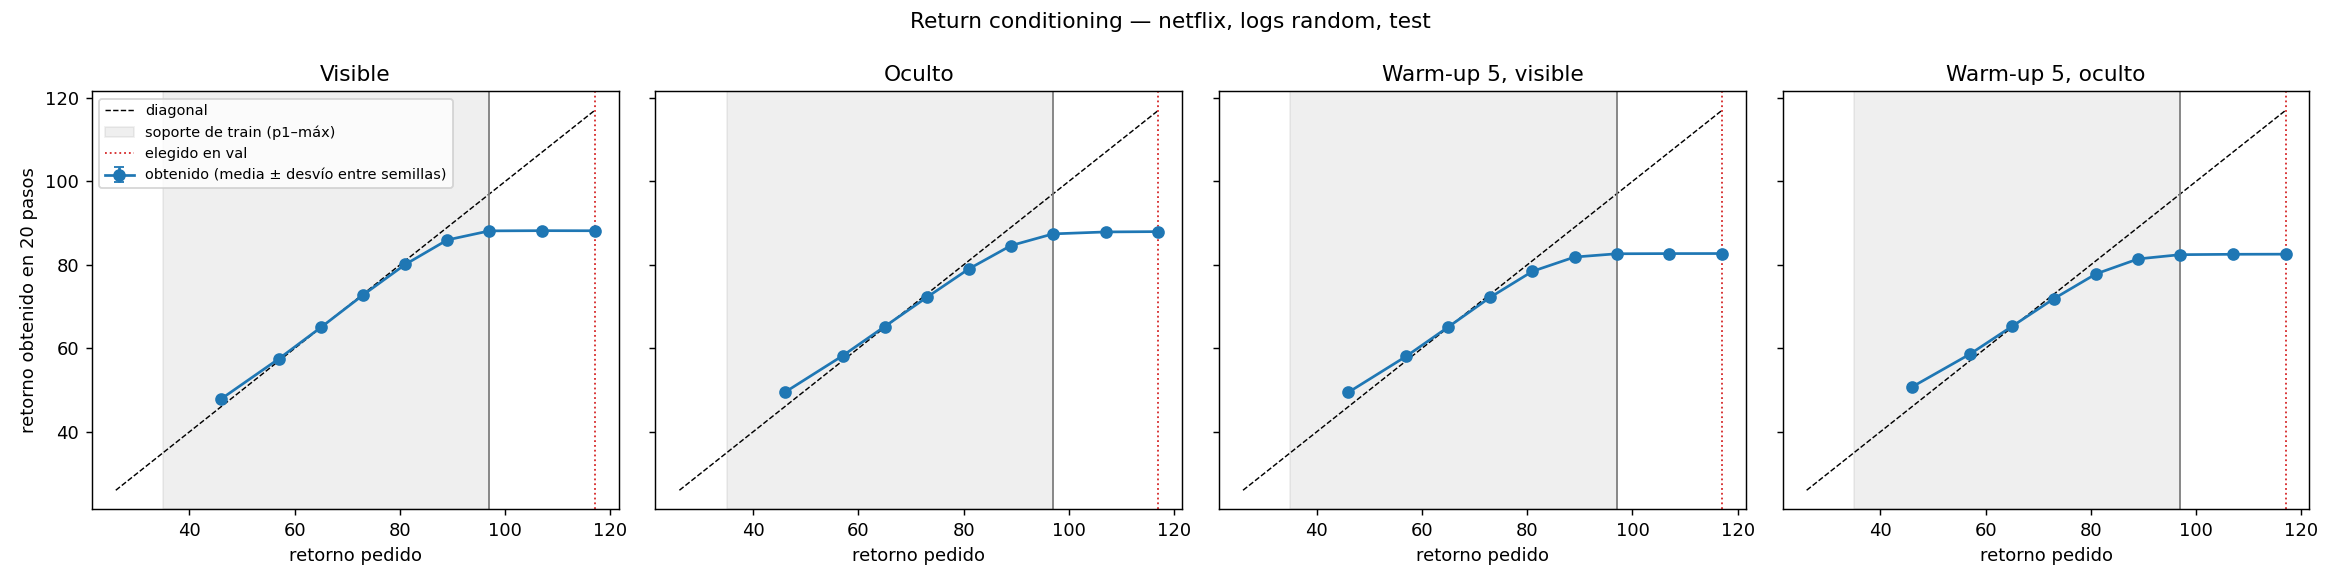

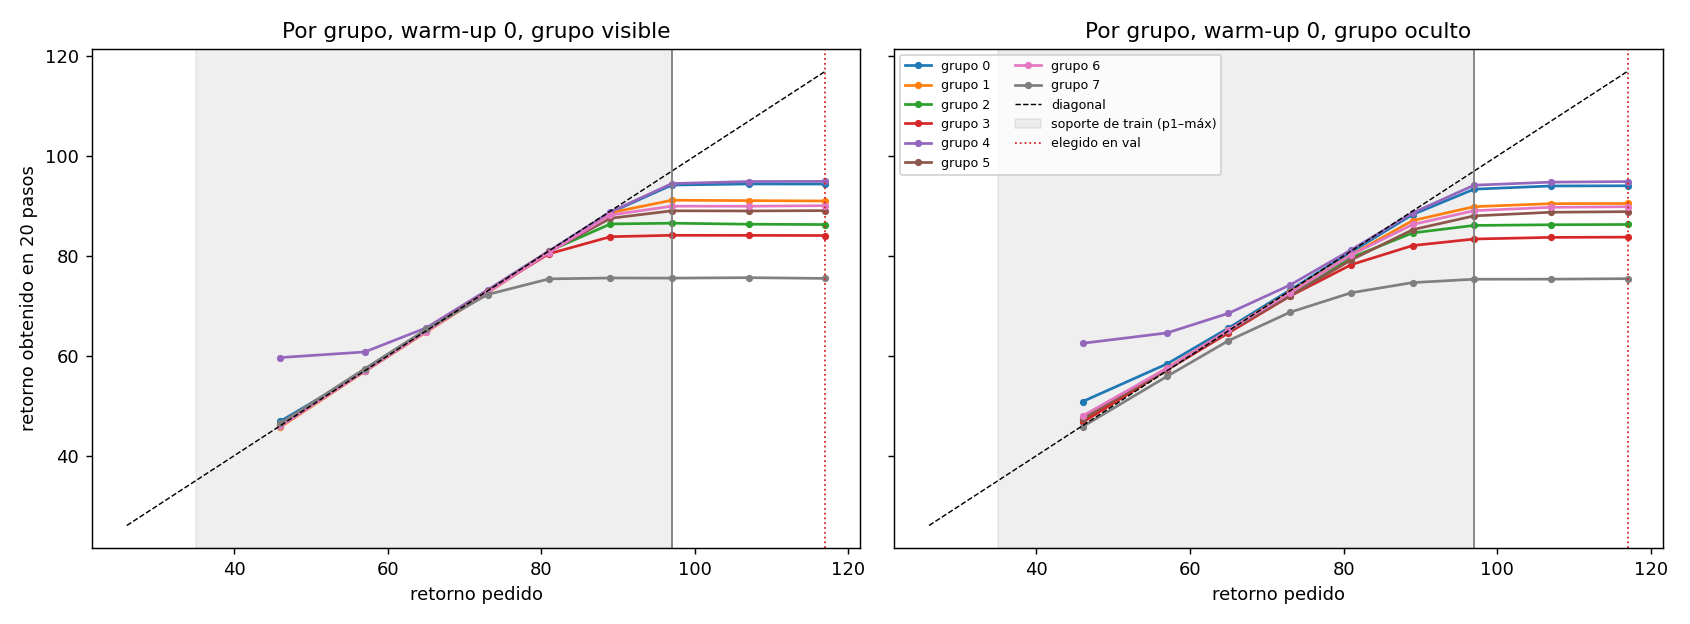

logs                         mixto         random        
cond                        oculto visible oculto visible
policy                                                   
DT (R̂ elegido en val.)      0.683   0.729  0.676   0.683
IQL máx. Q, γ = 0 (elegido)  0.673   0.730  0.669   0.728
IQL máx. Q, γ = 0.9          0.580   0.706  0.643   0.700
IQL π, γ = 0 (elegido)       0.667   0.737  0.643   0.703
IQL π, γ = 0.9               0.677   0.735  0.653   0.702
group_mean                   0.672   0.741  0.689   0.742
group_posterior              0.705   0.741  0.707   0.742
item_mean                    0.672   0.672  0.689   0.689
popularity                   0.688   0.688 -0.058  -0.058
random                      -0.002  -0.002 -0.002  -0.002
sistema_anterior_eps0        0.542   0.593    NaN     NaN


logs                         mixto         random        
cond                        oculto visible oculto visible
policy                                                   
DT (R̂ elegido en val.)      0.683   0.729  0.676   0.683
IQL máx. Q, γ = 0 (elegido)  0.673   0.730  0.669   0.728
IQL máx. Q, γ = 0.9          0.580   0.706  0.643   0.700
IQL π, γ = 0 (elegido)       0.667   0.737  0.643   0.703
IQL π, γ = 0.9               0.677   0.735  0.653   0.702
group_mean                   0.672   0.741  0.689   0.742
group_posterior              0.705   0.741  0.707   0.742
item_mean                    0.672   0.672  0.689   0.689
popularity                   0.688   0.688 -0.058  -0.058
random                      -0.002  -0.002 -0.002  -0.002
sistema_anterior_eps0        0.542   0.593    NaN     NaN

/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/dt/base/seed0/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/dt/base/seed1/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/dt/base/seed2/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0.9_t0.7_b10/seed0/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0.9_t0.7_b10/seed1/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0.9_t0.7_b10/seed2/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0_t0.7_b10/seed0/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0_t0.7_b10/seed1/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_mixto/iql/g0_t0.7_b10/seed2/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netflix_random/dt/base/seed0/curvas.png
/content/drive/MyDrive/tp_rl_2026/outputs/modelos/netfl

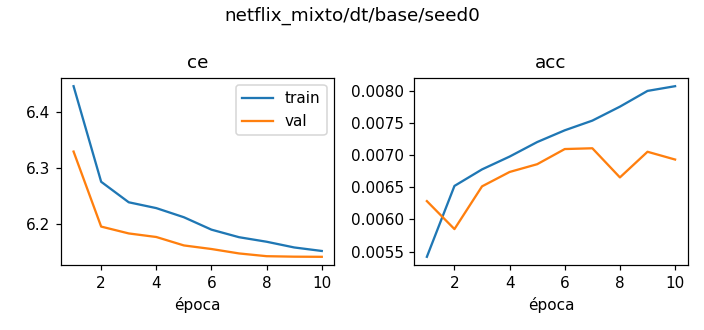

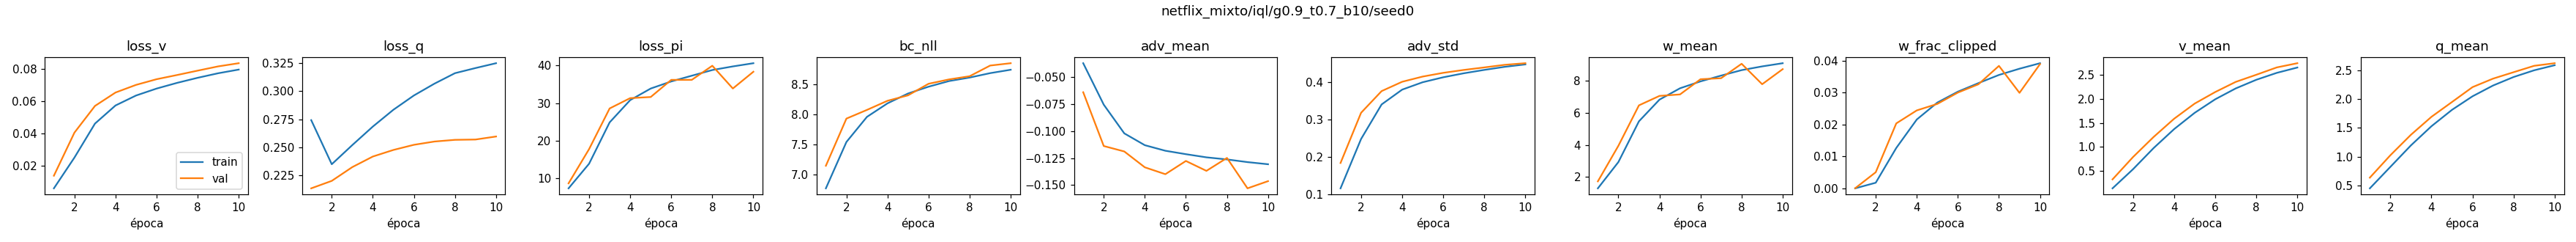

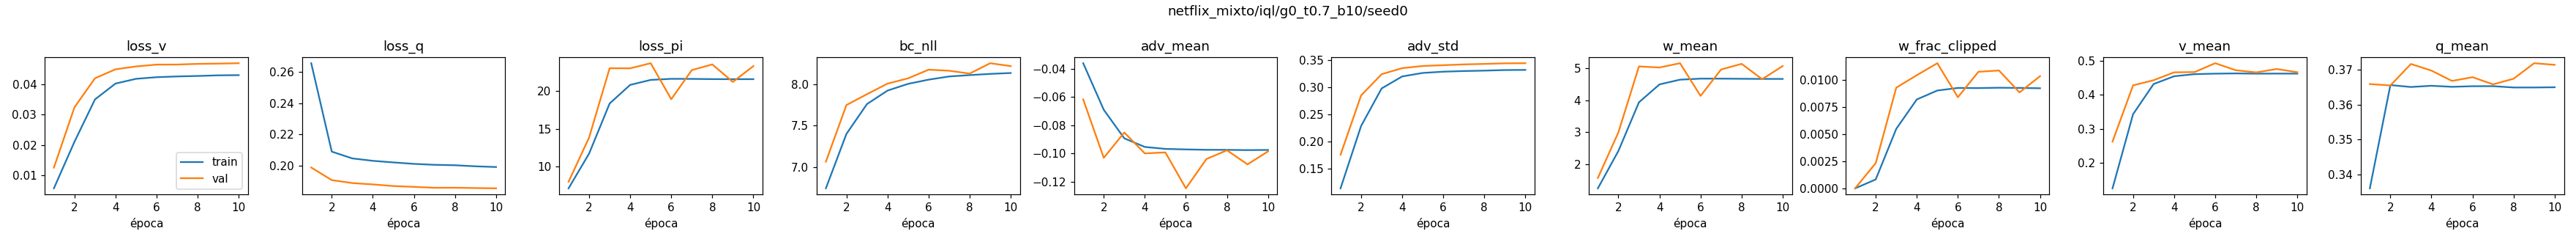

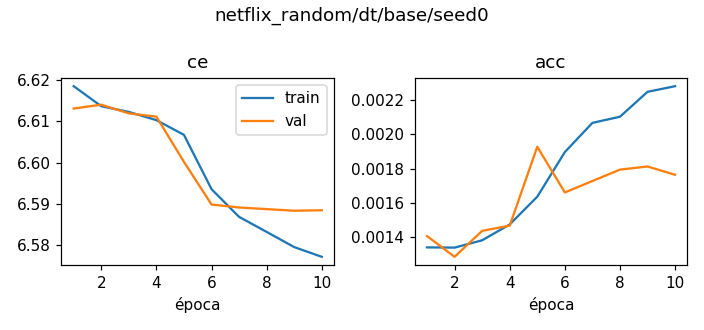

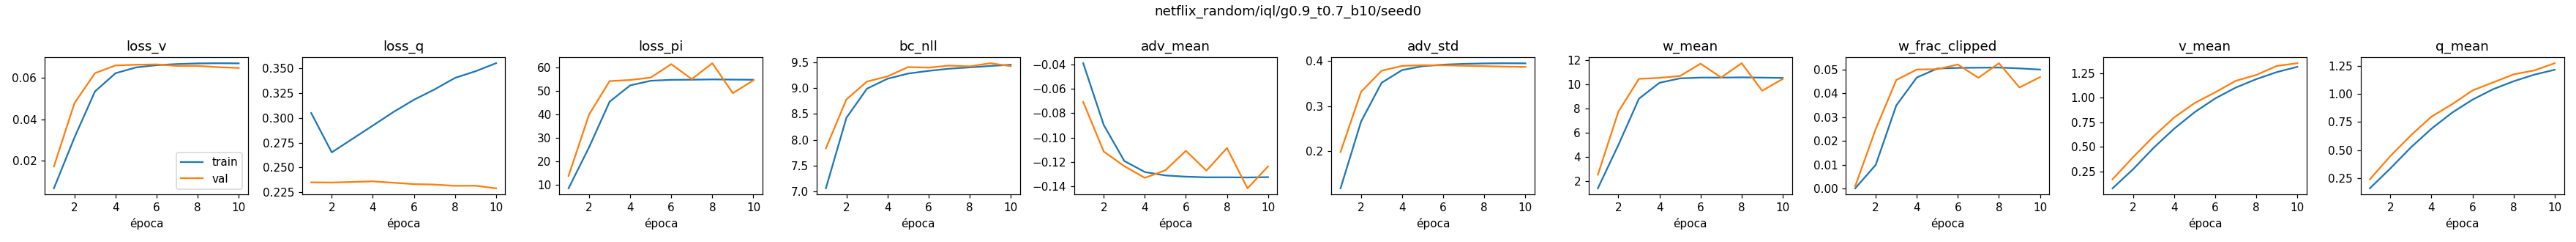

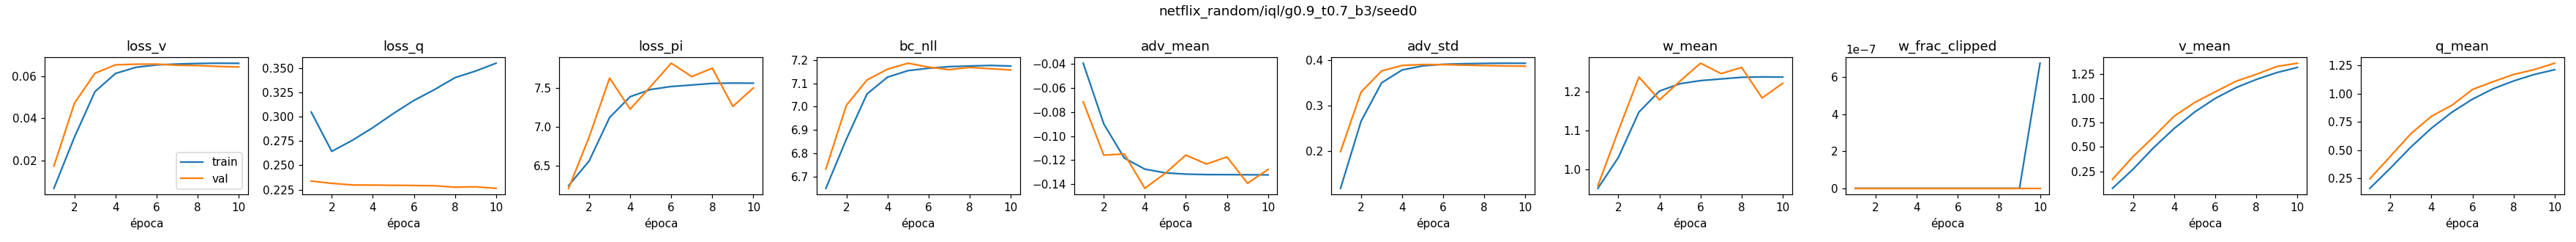

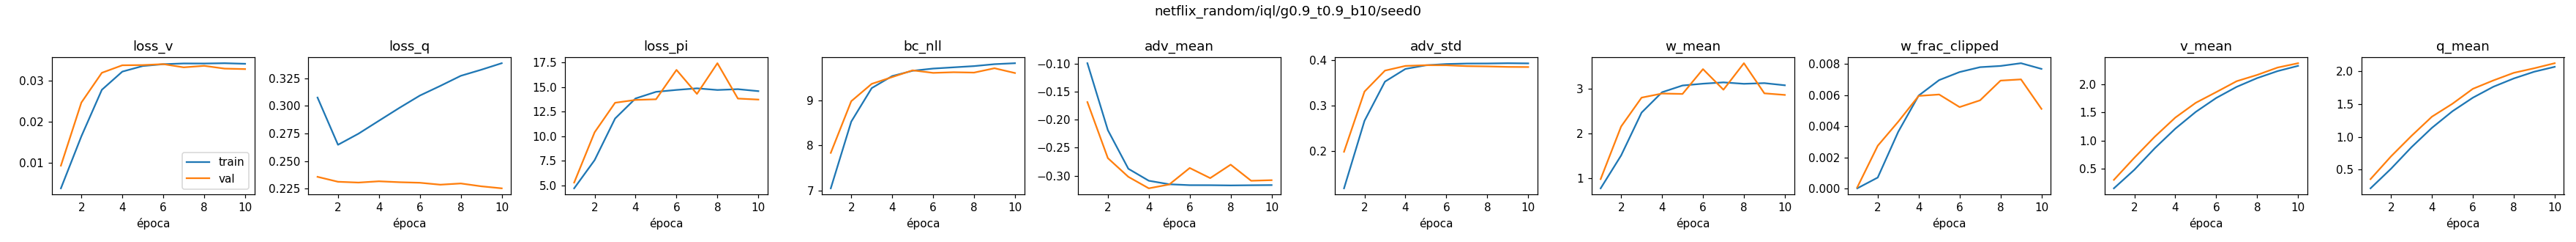

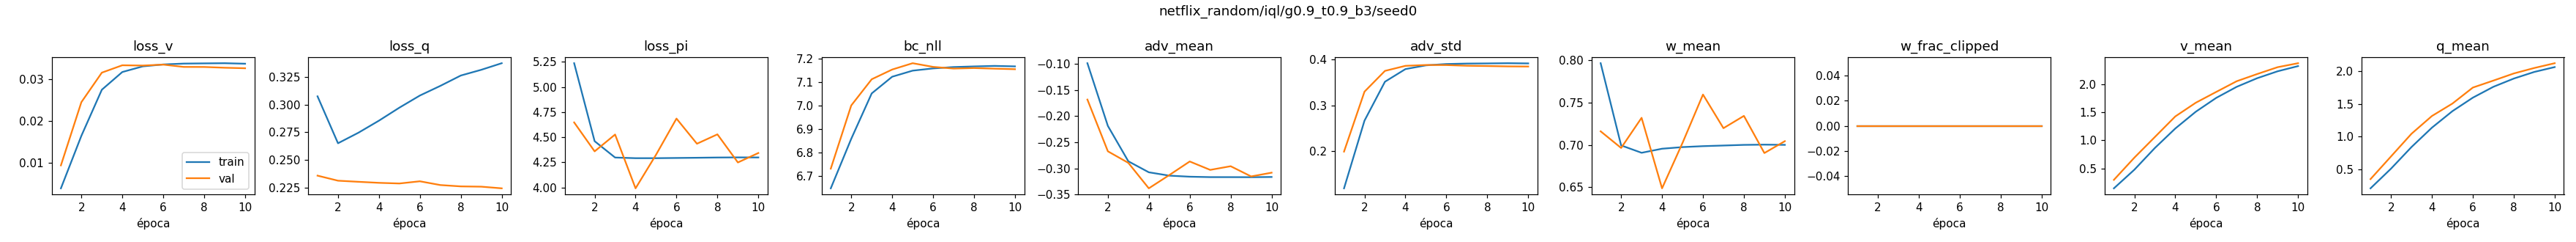

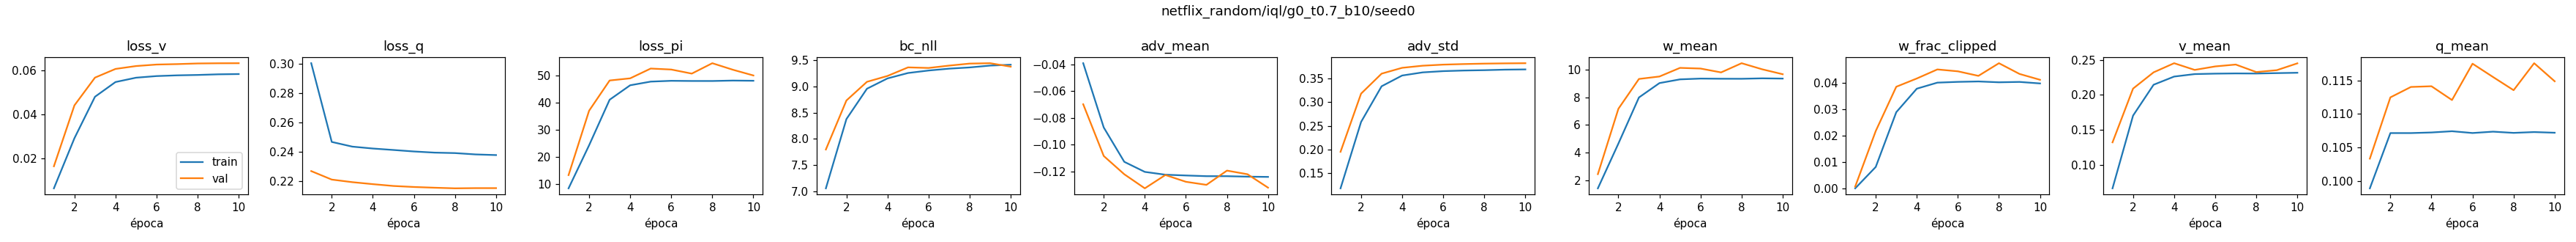

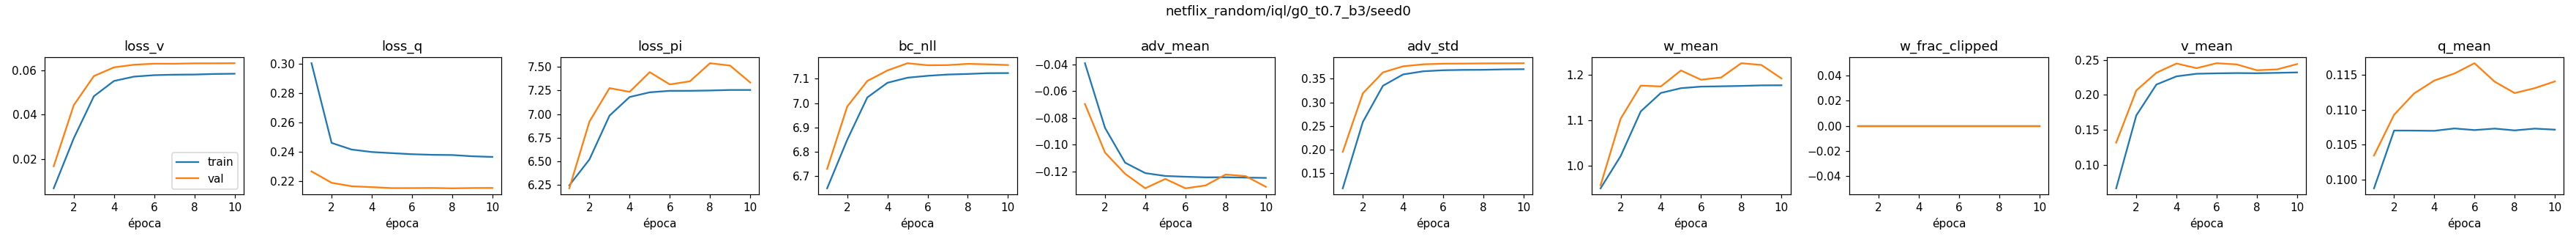

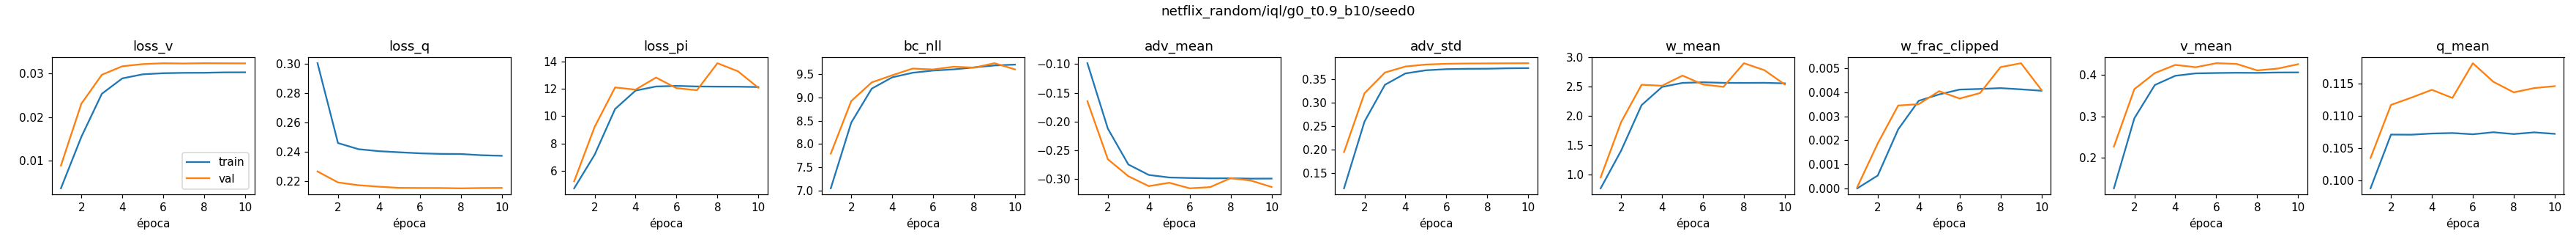

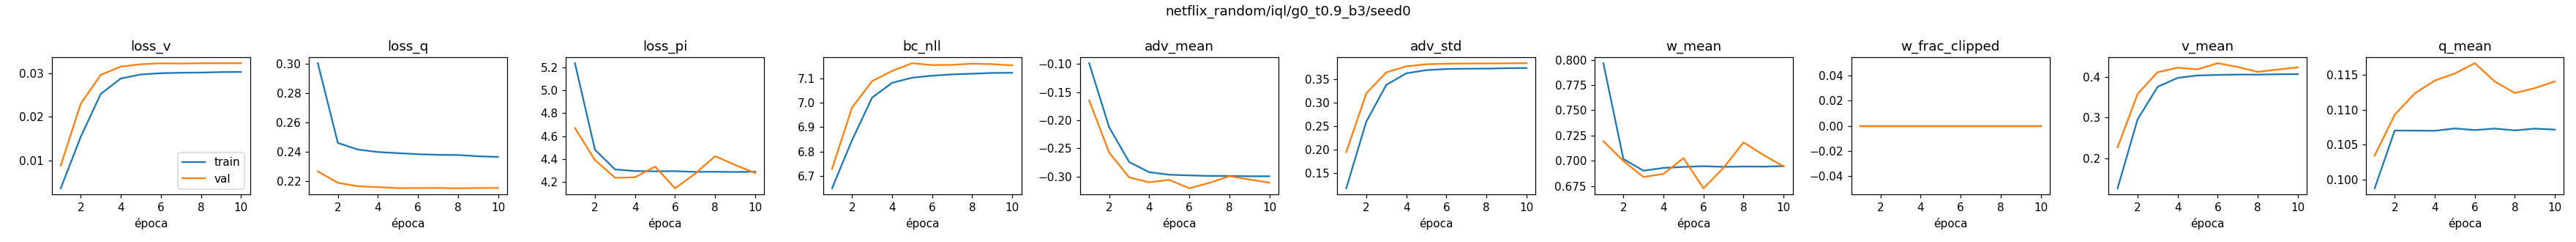

In [7]:
import glob
import pandas as pd
from IPython.display import Markdown, Image, display

OUT = os.environ["TP_OUTPUTS"]

# 1. Tablas finales: métrica principal y secundarias, para cada tipo de logs
for logs in ("random", "mixto"):
    for metric in ("normalized", "hit_rate", "ndcg@10"):
        correr(f"python -m modelos.reporte tabla --dataset {DATASET} --logs {logs} --metric {metric}")
        display(Markdown(open(f"{OUT}/{DATASET}_{logs}/final/tabla_{metric}.md", encoding="utf-8").read()))

# 2. Return conditioning del DT (logs random): pedido frente a obtenido, agregado y por grupo
correr(f"python -m modelos.reporte rc --dataset {DATASET} --logs random")
display(Image(f"{OUT}/{DATASET}_random/final/return_conditioning.png"))
display(Image(f"{OUT}/{DATASET}_random/final/return_conditioning_por_grupo.png"))

# 3. Calidad de los logs: normalized con warm-up 0, random frente a mixto
correr(f"python -m modelos.reporte logs --dataset {DATASET}")
display(pd.read_csv(f"{OUT}/{DATASET}_comparacion_logs/normalized_warmup0.csv",
                    header=[0, 1], index_col=0).round(3))

# 4. Curvas de entrenamiento de todas las corridas (también quedan como curvas.png en Drive)
runs = sorted(glob.glob(f"{OUT}/{DATASET}_*/dt/*/seed*") + glob.glob(f"{OUT}/{DATASET}_*/iql/*/seed*"))
correr("python -m modelos.reporte curvas " + " ".join(runs))
for run in runs:
    if run.endswith("seed0"):          # en pantalla, una semilla por configuración
        display(Image(f"{run}/curvas.png"))